# Jetsound: Sound detection with Jetson Nano

## Data collection and feature extraction

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import librosa

#DATADIR = 'music_dataset'
DATADIR = "../Haakons_testfolder/instrument_set"
print(DATADIR)
CATEGORIES = ['Acoustic_guitar', 'Drum_set', 'vibraphone']

../Haakons_testfolder/instrument_set


Function to make spectrograms.

In [3]:
def convert_to_spectrogram(audio_signal, sample_rate, n_mels, fmax=8000):
    # audio_signal
    # sample_rate
    # n_mels : mels bins (Y-resolution of spectrogram)
    # fmax : maximum frequency in spectrogram

    # Returns a 4D tensorflow tensor (1, n_mels, time_steps, 1)
        
    # Create mel spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y = audio_signal,
        sr = sample_rate,
        n_mels = n_mels,
        fmax = fmax
    )
    
    # Convert to decibels
    mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    # Normalize
    mel_spec = (mel_spec - mel_spec.min()) / (mel_spec.max() - mel_spec.min())

    # Add channel dimension
    mel_spec = mel_spec[..., np.newaxis]  # shape: (n_mels, time_steps, 1)

    # Add batch dimension
    return mel_spec[np.newaxis, ...]

In [14]:
dataset = []
N_MELS = 128 # Y resolution of the spectrograms (basically image height)
T_SAMP = 300 # X resolution of the spectrograms (basically image width)

def create_dataset():
    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        class_num = CATEGORIES.index(category) #Assigns category 0 to Autistic_guitar, 1 to Drum_set and 2 to vibraphone
        for audio_sample in os.listdir(path):
            try:
                audio, sr = librosa.load(os.path.join(path, audio_sample))
                spectro = convert_to_spectrogram(audio, sr, N_MELS, fmax=8000)
                dataset.append([spectro, class_num, sr]) # Appends the category to the array
                print(audio_sample)
            except Exception as e:
                pass
    
create_dataset()

print(len(dataset))

1.wav
10.wav
100.wav
101.wav
102.wav
103.wav
104.wav
105.wav
106.wav
107.wav
108.wav
109.wav
11.wav
110.wav
111.wav
112.wav
113.wav
114.wav
115.wav
116.wav
117.wav
118.wav
119.wav
12.wav
120.wav
121.wav
122.wav
123.wav
124.wav
125.wav
126.wav
127.wav
128.wav
129.wav
13.wav
130.wav
131.wav
132.wav
133.wav
134.wav
135.wav
136.wav
137.wav
138.wav
139.wav
14.wav
140.wav
141.wav
142.wav
143.wav
144.wav
145.wav
146.wav
147.wav
148.wav
149.wav
15.wav
150.wav
151.wav
152.wav
153.wav
154.wav
155.wav
156.wav
157.wav
158.wav
159.wav
16.wav
160.wav
161.wav
162.wav
163.wav
164.wav
165.wav
166.wav
167.wav
168.wav
169.wav
17.wav
170.wav
171.wav
172.wav
173.wav
174.wav
175.wav
176.wav
177.wav
178.wav
179.wav
18.wav
180.wav
181.wav
182.wav
183.wav
184.wav
185.wav
186.wav
187.wav
188.wav
189.wav
19.wav
190.wav
191.wav
192.wav
193.wav
194.wav
195.wav
196.wav
197.wav
198.wav
199.wav
2.wav
20.wav
200.wav
201.wav
202.wav
203.wav
204.wav
205.wav
206.wav
207.wav
208.wav
209.wav
21.wav
210.wav
211.wav
212.wav


Show example from new dataset


22050
Category: vibraphone


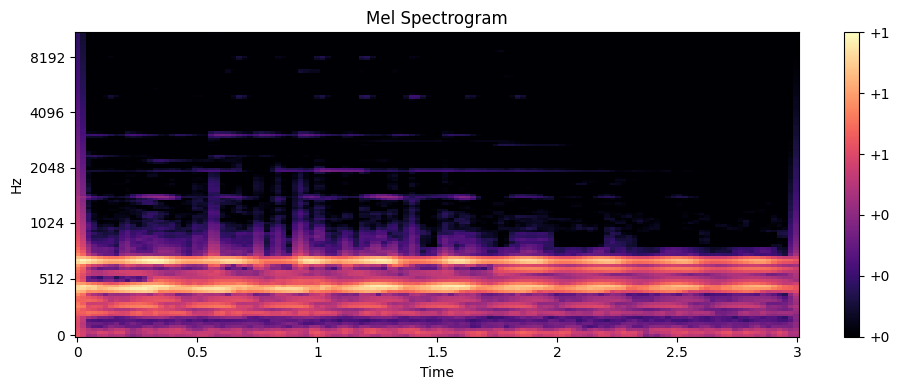

In [25]:
CHOSEN_EXAMPLE = 1501

print(dataset[0][2])
print("Category: " + CATEGORIES[dataset[CHOSEN_EXAMPLE][1]])

# Remove batch and channel dimensions
spec = dataset[CHOSEN_EXAMPLE][0]
spec = spec[0, :, :, 0]

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    spec,
    x_axis="time",
    y_axis="mel",
    sr=dataset[CHOSEN_EXAMPLE][2]
)
plt.colorbar(format="%+2.0f")
plt.title("Mel Spectrogram")
plt.tight_layout()
plt.show()

Shuffle the dataset and make sure by looking at the labels.

In [26]:
import random

random.shuffle(dataset)

for sample in dataset[:10]:
    print(sample[1])

0
0
0
0
2
0
0
1
2
1


Create your train and test split.

In [27]:
x = [] #Images
y = [] #Labels

for features, label in dataset:
    x.append(features)  #Place all images in x
    y.append(label)     #Place all labels in y

x = np.array(x).reshape(-1, N_MELS, IMG_SIZE, 1)
y = np.array(y)

# We have to split the data for testing
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.1, random_state=42)

ValueError: too many values to unpack (expected 2)

## Network architecture

## Model training

In [ ]:
# Model definition
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(N_MELS, tensor.shape[2], 1)),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(NUMBER_OF_CLASSES, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

## Validation

You need the library "pyaudio" to test this feature.

    pip install pyaudio
    
    conda install conda-forge::pyaudio

In [ ]:
import pyaudio
import wave

# Configuration parameters
FORMAT = pyaudio.paInt16  # 16-bit resolution
CHANNELS = 1              # Mono recording
RATE = 44100              # Sample rate (44.1kHz is standard)
CHUNK = 1024              # Buffer size
RECORD_SECONDS = 5        # Duration of recording
OUTPUT_FILENAME = "test_recording.wav"

audio = pyaudio.PyAudio()

# Start Recording
stream = audio.open(format=FORMAT, channels=CHANNELS,
                    rate=RATE, input=True,
                    frames_per_buffer=CHUNK)

print("Recording...")

frames = []

for i in range(0, int(RATE / CHUNK * RECORD_SECONDS)):
    data = stream.read(CHUNK)
    frames.append(data)

print("Finished recording.")

# Stop and close the stream
stream.stop_stream()
stream.close()
audio.terminate()

# Save the recorded data as a WAV file 
# (THIS NEEDS TO BE CHANGED SO IT IS STORED IN MEMORY TO BE USED IN REAL TIME)
with wave.open(OUTPUT_FILENAME, 'wb') as wf:
    wf.setnchannels(CHANNELS)
    wf.setsampwidth(audio.get_sample_size(FORMAT))
    wf.setframerate(RATE)
    wf.writeframes(b''.join(frames))

print(f"File saved as {OUTPUT_FILENAME}")

Recording...
Finished recording.
File saved as test_recording.wav
